In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LogNorm
import torch
from torch import nn
from torch import optim
import torch.optim.lr_scheduler as lr_scheduler
import torch.nn.functional as F
from torchvision import transforms as T
from torchvision import models
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import confusion_matrix, roc_curve, auc
from sklearn.manifold import TSNE, Isomap
import glob
#from astropy.visualization import simple_norm
#import os
#from torchvision.io import read_image
from tqdm import tqdm
import pandas as pd
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
from torchsummary import summary


In [2]:
# Load the saved model state
checkpoint = torch.load('ResNet18CNN.pth', map_location=torch.device('cpu'))
model = models.resnet18(pretrained=True)
#Set up the model for inference
model.fc = nn.Linear(512, 1)  # Ensure the output layer is the same

# Load the model weights from the checkpoint
model.load_state_dict(checkpoint['model_state_dict'])
model = model.to('cpu')  # Ensure the model is on the correct device (GPU/CPU)
model.eval()  # Switch to evaluation mode

device = 'cuda' if torch.cuda.is_available() else 'cpu'

/n/home09/aschechter/.conda/envs/py38/lib/python3.8/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/n/home09/aschechter/.conda/envs/py38/lib/python3.8/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [3]:
from BinaryMergerDataset import BinaryMergerDataset, get_transforms
path = '/n/holystore01/LABS/hernquist_lab/Users/aschechter/z1widebinmocks/'
BATCH_SIZE = 64

cpu


In [4]:
test_mergers_dataset_orig = BinaryMergerDataset(path, 'test', mergers = True, transform = get_transforms(aug=False), codetest=False)
test_nonmergers_dataset_orig = BinaryMergerDataset(path, 'test', mergers = False, transform = get_transforms(aug=False), codetest=False)

test_dataset_full = torch.utils.data.ConcatDataset([test_mergers_dataset_orig, test_nonmergers_dataset_orig])
test_dataloader = DataLoader(test_dataset_full, shuffle = True, num_workers = 0, batch_size=BATCH_SIZE)#num workers used to be 4


In [5]:

def get_accuracy(pred,original):
    #pred = (torch.sigmoid(pred) > 0.5).float() #pred is now 0 or 1
    #pred = pred.numpy()
    #original = original.numpy()
    # print(type(pred))
    # print(type(original))
    if type(pred) != type(original):
        return np.nan
    else:
        return np.mean(pred == original) * 100

def plot_confusion_matrix(cm, classes, epoch): #help from chat GPT
    plt.figure(figsize=(5, 5))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap='Purples', xticklabels=classes, yticklabels=classes, vmin = 0, vmax = 100,
                square = True, cbar_kws={'label': 'Percentage'})
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.title('Confusion Matrix ' + str(epoch) + ' Set')
    plt.savefig('ConfusionMatrix_TestSet.png', dpi = 300)
    plt.show()

In [6]:
all_labels = []
all_preds = []
all_names = []
all_probabilities = []


with torch.no_grad():  # No need to track gradients during inference
    for images, labels, names in tqdm(test_dataloader):
        #print(type(names))
        images = torch.tensor(images, dtype=torch.float32).to(device)
        labels = torch.tensor(labels, dtype=torch.float32).to(device)
        # Forward pass
        outputs = model(images)
        # print(type(outputs))
        # print(outputs.shape)
        probabilities = torch.sigmoid(outputs)
        pred = (probabilities > 0.5).float()  # Convert to binary (0 or 1)
        pred = pred.to(device=device, dtype=torch.float32)
        # Collect labels and predictions
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(pred.cpu().numpy())
        all_names.extend(names)
        all_probabilities.extend(probabilities.cpu().numpy())
# 4. Compute accuracy or other evaluation metrics (e.g., confusion matrix)
# Convert lists to numpy arrays
all_labels = np.array(all_labels)
all_preds = np.squeeze(np.array(all_preds))
all_names = np.array(all_names)
test_accuracy = get_accuracy(all_preds, all_labels)
#test_accuracy = np.mean(np.array(test_acc))
print(f"Test Accuracy: {test_accuracy:.2f}%")


  0%|          | 0/14 [00:00<?, ?it/s]/tmp/ipykernel_4078621/275184019.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  images = torch.tensor(images, dtype=torch.float32).to(device)
/tmp/ipykernel_4078621/275184019.py:11: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(labels, dtype=torch.float32).to(device)
100%|██████████| 14/14 [01:18<00:00,  5.62s/it]

Test Accuracy: 66.55%


In [7]:
# Convert lists to numpy arrays
all_labels = np.array(all_labels)
all_preds = np.array(all_preds)
all_names = np.array(all_names)

In [8]:
print(np.shape(all_labels))

(840,)


In [9]:
print(np.shape(np.squeeze(all_preds)))

(840,)


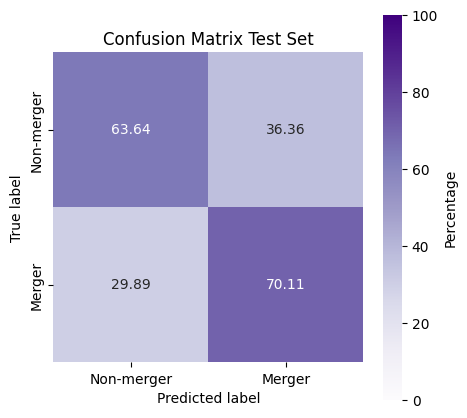

In [10]:

cm = confusion_matrix(all_labels, all_preds)
cmn = (cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]) *100 
plot_confusion_matrix(cmn, classes=['Non-merger', 'Merger'], epoch='Test')


In [11]:
print(len(all_probabilities))

840


[0.         0.         0.0021645  0.0021645  0.004329   0.004329
 0.00649351 0.00649351 0.01082251 0.01082251 0.01298701 0.01298701
 0.01515152 0.01515152 0.01731602 0.01731602 0.01948052 0.01948052
 0.02597403 0.02597403 0.03030303 0.03030303 0.03246753 0.03246753
 0.03463203 0.03463203 0.03679654 0.03679654 0.03896104 0.03896104
 0.04329004 0.04329004 0.04545455 0.04545455 0.04761905 0.04761905
 0.04978355 0.04978355 0.05194805 0.05194805 0.05844156 0.05844156
 0.06060606 0.06060606 0.06277056 0.06277056 0.06493506 0.06493506
 0.06709957 0.06709957 0.07142857 0.07142857 0.07359307 0.07359307
 0.08008658 0.08008658 0.09307359 0.09307359 0.0974026  0.0974026
 0.0995671  0.0995671  0.1017316  0.1017316  0.1038961  0.1038961
 0.10822511 0.10822511 0.11038961 0.11038961 0.11471861 0.11471861
 0.11904762 0.11904762 0.12121212 0.12121212 0.12337662 0.12337662
 0.12554113 0.12554113 0.12770563 0.12770563 0.13203463 0.13203463
 0.13636364 0.13636364 0.13852814 0.13852814 0.14069264 0.14069264

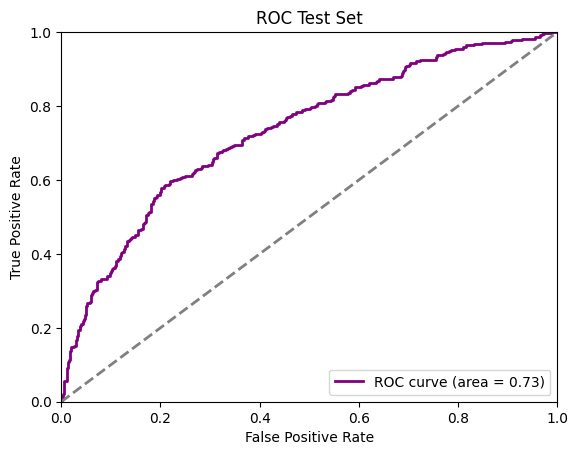

In [12]:
fpr, tpr, thresholds = roc_curve(all_labels, all_probabilities)
area = auc(fpr, tpr)
print(fpr, tpr, area)
# Plot ROC curve
plt.figure()
plt.plot(fpr, tpr, color='purple', lw=2, label='ROC curve (area = %0.2f)' % area)
plt.plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Test Set')
plt.legend(loc="lower right")
plt.savefig('ROC_Test.png', dpi = 300)
plt.show()

In [13]:
correct = []
for i in range(len(all_preds)):
    if all_preds[i] == all_labels[i]:
        correct.append('yes')
    else:
        correct.append('no')

In [14]:
ClassificationInfo = pd.DataFrame(all_names, columns=['Image Name'])
ClassificationInfo['True Label'] = all_labels
ClassificationInfo['Predicted Label'] = all_preds
ClassificationInfo['Correct?'] = correct
ClassificationInfo = ClassificationInfo.sort_values(by='Image Name')

ClassificationInfo

,Image Name,True Label,Predicted Label,Correct?
389,102575_1,0.0,0.0,yes
3,102575_2,0.0,0.0,yes
162,102575_3,0.0,0.0,yes
304,102575_4,0.0,1.0,no
484,102575_5,0.0,0.0,yes
...,...,...,...,...
627,9_2,0.0,0.0,yes
591,9_3,0.0,0.0,yes
168,9_4,0.0,0.0,yes
396,9_5,0.0,0.0,yes


In [15]:
shids = []
for n in ClassificationInfo['Image Name']:
    #print(n[:-2])
    shids.append(n[:-2])
shids = list(set(shids))
shids = np.array(shids).astype(int)
print(shids)

[ 59054 437412     64 488529 185878 640580 133930 491236 581560 488583
 332258 249507 633635 302219 547945 482765 308108 549751 541720 439300
 485035 310743 582283 529231 505878 386422 287085 343327  44902 347601
  51921 534436 531125 563435 568162 183284 431805 576456 563290 579286
 474784 526267 423389 573635 600936 287270 426386 439505 260976 493072
 171738 323921 492232 248318 431422 184632 554974  95939 364146 635559
 473897 476424 549791 255869 600457 494445 479302 156297 323149 537172
 608551 339351 515835 446367 377976 165282 463021 539740 575769 251038
 137028 554414     16 488282 319239 431683 374021 549564 553124 580431
 576396 314451 553851 513537 288065 416310 213279 517090 489758 227628
 620165 579023 422061  36236 376727 399366 566528 456523 392480 102575
 625897 477522 616147      9 446589 269433 393375 605039  68961 282874
 239266 465275 552237 537731 488076 440457 407434 212082 573975 361371
  93692 596479 526221 309514 447350 540520 435395 286318 110114 651137]


In [16]:
table40 = pd.read_csv('/n/home09/aschechter/code/SubhaloListForMakeMocks40.csv', usecols = ['Subfind_ID', 'Type'])
table50 = pd.read_csv('/n/home09/aschechter/code/SubhaloListForMakeMocks50.csv', usecols = ['Subfind_ID', 'Type'])
bigtable = pd.concat([table40, table50], ignore_index=False)
bigtable

,Subfind_ID,Type
0,289514,Descendant
1,289514,Descendant
2,289514,Descendant
3,289514,Descendant
4,289514,Descendant
...,...,...
3115,118843,0.0
3116,118843,0.0
3117,118843,0.0
3118,118843,0.0


In [17]:
print(type(bigtable['Subfind_ID'][0]))
print(type(shids[0]))

<class 'pandas.core.series.Series'>
<class 'numpy.int64'>


In [18]:
types =[]
for s in shids:
    #print(type(s))
    limit = 6
    result = bigtable.loc[bigtable['Subfind_ID'] == s, 'Type'].values[0]
    print(result)
    while limit != 0:
        types.append(result)
        limit-=1
    

0.0
Descendant
Merger
Descendant
0.0
0.0
0.0
Descendant
0.0
first_progenitor
0.0
0.0
Merger
0.0
first_progenitor
0.0
0.0
Merger
0.0
0.0
first_progenitor
Descendant
Descendant
Descendant
Descendant
0.0
next_progenitor
0.0
0.0
0.0
0.0
0.0
Descendant
Merger
Merger
first_progenitor
first_progenitor
0.0
first_progenitor
Descendant
Merger
first_progenitor
Descendant
0.0
0.0
0.0
Merger
0.0
Merger
first_progenitor
first_progenitor
next_progenitor
0.0
Descendant
first_progenitor
next_progenitor
Descendant
0.0
0.0
0.0
0.0
first_progenitor
first_progenitor
0.0
0.0
first_progenitor
0.0
0.0
Merger
Descendant
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
Descendant
Descendant
0.0
Merger
0.0
Merger
first_progenitor
0.0
first_progenitor
Descendant
0.0
Merger
0.0
first_progenitor
0.0
0.0
Merger
0.0
first_progenitor
0.0
first_progenitor
Merger
Descendant
Descendant
Descendant
Descendant
0.0
next_progenitor
0.0
first_progenitor
0.0
next_progenitor
0.0
first_progenitor
Descendant
first_progenitor
first_progenitor
first

In [19]:
print(len(types))
ClassificationInfo['Type'] = types
ClassificationInfo

840


,Image Name,True Label,Predicted Label,Correct?,Type
389,102575_1,0.0,0.0,yes,0.0
3,102575_2,0.0,0.0,yes,0.0
162,102575_3,0.0,0.0,yes,0.0
304,102575_4,0.0,1.0,no,0.0
484,102575_5,0.0,0.0,yes,0.0
...,...,...,...,...,...
627,9_2,0.0,0.0,yes,0.0
591,9_3,0.0,0.0,yes,0.0
168,9_4,0.0,0.0,yes,0.0
396,9_5,0.0,0.0,yes,0.0


### Add Merger Mass Ratio

In [20]:
s_main = 40
s = 40
Subfind_ID_mergers40 = np.loadtxt('/n/home09/aschechter/TNGProjects/merger_tables/' + str(s_main) + '/all_mergers_at_' + str(s) + '_enviro.txt', 
                                    skiprows = 1, usecols = 1, dtype = int)
q_mergers40 = np.loadtxt('/n/home09/aschechter/TNGProjects/merger_tables/' + str(s_main) + '/all_mergers_at_' + str(s) + '_enviro.txt', 
                                    skiprows = 1, usecols = 3, dtype = float)
s_main = 50
s = 50
Subfind_ID_mergers50 = np.loadtxt('/n/home09/aschechter/TNGProjects/merger_tables/' + str(s_main) + '/all_mergers_at_' + str(s) + '_enviro.txt', 
                                    skiprows = 1, usecols = 1, dtype = int)
q_mergers50 = np.loadtxt('/n/home09/aschechter/TNGProjects/merger_tables/' + str(s_main) + '/all_mergers_at_' + str(s) + '_enviro.txt', 
                                    skiprows = 1, usecols = 3, dtype = float)

In [21]:
q= []
Subfind_ID = np.concatenate((Subfind_ID_mergers40, Subfind_ID_mergers50))
q_mergers = np.concatenate((q_mergers40, q_mergers50))

for s in shids:
    #print(type(s))
    limit = 6
    if s in Subfind_ID:
        index = np.where(Subfind_ID == s)[0][0]
        #print(index[0][0])
        ratio = q_mergers[index]
        if ratio < 1:
            while limit != 0:
                q.append(ratio) 
                limit-=1     
        else:
            while limit != 0:
                q.append(1/ratio)
                limit-=1
    else:
        while limit != 0:
            q.append(0.0)
            limit-=1

q_name = []
for r in q:
    if r== 0.0:
        q_name.append('non')
    elif r >= 0.25:
        q_name.append('major')
    else: 
        q_name.append('minor')
#print(len(q))
ClassificationInfo['Mass Ratio'] = q
ClassificationInfo['Ratio Name'] = q_name

In [22]:
ClassificationInfo

,Image Name,True Label,Predicted Label,Correct?,Type,Mass Ratio,Ratio Name
389,102575_1,0.0,0.0,yes,0.0,0.0,non
3,102575_2,0.0,0.0,yes,0.0,0.0,non
162,102575_3,0.0,0.0,yes,0.0,0.0,non
304,102575_4,0.0,1.0,no,0.0,0.0,non
484,102575_5,0.0,0.0,yes,0.0,0.0,non
...,...,...,...,...,...,...,...
627,9_2,0.0,0.0,yes,0.0,0.0,non
591,9_3,0.0,0.0,yes,0.0,0.0,non
168,9_4,0.0,0.0,yes,0.0,0.0,non
396,9_5,0.0,0.0,yes,0.0,0.0,non


In [23]:
p_class = []
t_class = []

for l in ClassificationInfo['True Label']:
    if l == 0.0:
        t_class.append('merger')
    else:
        t_class.append('nonmerger')

for l in ClassificationInfo['Predicted Label']:
    if l == 0.0:
        p_class.append('merger')
    else:
        p_class.append('nonmerger')

ClassificationInfo['True Class'] = t_class
ClassificationInfo['Predicted Class'] = p_class

In [24]:
ClassificationInfo = ClassificationInfo.loc[:, ['Image Name', 'True Class', 'Predicted Class', 'True Label', 'Predicted Label', 'Correct?', 'Type', 'Mass Ratio', 'Ratio Name']]

In [25]:
ClassificationInfo

,Image Name,True Class,Predicted Class,True Label,Predicted Label,Correct?,Type,Mass Ratio,Ratio Name
389,102575_1,merger,merger,0.0,0.0,yes,0.0,0.0,non
3,102575_2,merger,merger,0.0,0.0,yes,0.0,0.0,non
162,102575_3,merger,merger,0.0,0.0,yes,0.0,0.0,non
304,102575_4,merger,nonmerger,0.0,1.0,no,0.0,0.0,non
484,102575_5,merger,merger,0.0,0.0,yes,0.0,0.0,non
...,...,...,...,...,...,...,...,...,...
627,9_2,merger,merger,0.0,0.0,yes,0.0,0.0,non
591,9_3,merger,merger,0.0,0.0,yes,0.0,0.0,non
168,9_4,merger,merger,0.0,0.0,yes,0.0,0.0,non
396,9_5,merger,merger,0.0,0.0,yes,0.0,0.0,non


In [26]:
ClassificationInfo.to_csv('CNN_ResultsTable.csv', index=False)

#### How do we do on major vs minor mergers?

In [33]:
major = ClassificationInfo[ClassificationInfo['Ratio Name'] == 'major']
minor = ClassificationInfo[ClassificationInfo['Ratio Name'] == 'minor']

major_correct = major[major['Correct?'] == 'yes']
minor_correct = minor[minor['Correct?'] == 'yes']

major_accuracy = np.round(len(major_correct)/len(major) *100, 2)
minor_accuracy = np.round(len(minor_correct)/len(minor)*100, 2)

print(major_accuracy)
print(minor_accuracy)

70.2
67.42


In [28]:
corrects = ClassificationInfo[ClassificationInfo['Correct?'] == 'yes']
print(len(corrects)/len(ClassificationInfo))

0.6654761904761904


#### How do we do on different merger stages?

In [32]:
merger= ClassificationInfo[ClassificationInfo['Type'] == 'Merger']
early = ClassificationInfo[(ClassificationInfo['Type'] == 'first_progenitor') | (ClassificationInfo['Type'] == 'next_progenitor')] #| is or but better for this case
late = ClassificationInfo[ClassificationInfo['Type'] == 'Descendant']

merger_correct = merger[merger['Correct?'] == 'yes']
early_correct = early[early['Correct?'] == 'yes']
late_correct = late[late['Correct?'] == 'yes']

merger_accuracy = np.round(len(merger_correct)/len(merger) *100,2)
early_accuracy = np.round(len(early_correct)/len(early)*100,2)
late_accuracy = np.round(len(late_correct)/len(late)*100,2)



print(merger_accuracy)
print(early_accuracy)
print(late_accuracy)

80.21
62.12
69.64


In [30]:
post = ClassificationInfo[(ClassificationInfo['Type'] == 'Merger') | (ClassificationInfo['Type'] == 'Descendant')] #| is or but better for this case
post_correct = post[post['Correct?'] == 'yes']
post_accuracy = len(post_correct)/len(post)
print(post_accuracy)

0.7348484848484849
